In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

(2, 100) (1, 100)


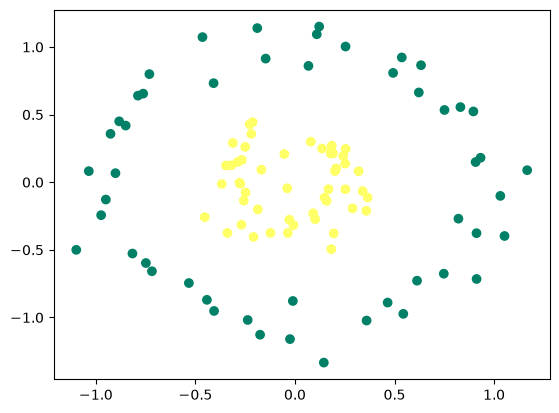

In [13]:
X, y = make_circles(n_samples = 100, noise = 0.1, factor = 0.3, random_state = 0)

#convention 2 : column version
X = X.T 
y = y.reshape(1, y.shape[0])
print(X.shape, y.shape)

plt.scatter(X[0,:], X[1,:], c=y, cmap='summer')
plt.show()

In [14]:
def initialisation(dimensions) :

    parameters = {}
    C = len(dimensions)

    for i in range (1, C) :
        parameters['W' + str(i)] = np.random.randn(dimensions[i], dimensions[i-1])
        parameters['b' + str(i)] = np.random.randn(dimensions[i], 1)

    return parameters

In [15]:
parameters = initialisation([2, 32, 32, 1])

for key, value in parameters.items() :    #.items to take both key and value
    print('dimensions of ', key, ' are ', value.shape)

dimensions of  W1  are  (32, 2)
dimensions of  b1  are  (32, 1)
dimensions of  W2  are  (32, 32)
dimensions of  b2  are  (32, 1)
dimensions of  W3  are  (1, 32)
dimensions of  b3  are  (1, 1)


In [16]:
def forward_propagation(X,parameters) :

    C = len(parameters) // 2
    activations = {'A0' : X}

    for i in range(1, C + 1) :
        Z = parameters['W' + str(i)].dot(activations['A' + str(i - 1)]) + parameters['b' + str(i)]
        A = 1 / (1 + np.exp(-Z))
        activations['A' + str(i)] = A
        
    return activations

In [17]:
activations = forward_propagation(X, parameters)

for key, value in activations.items() :
    print('dimensions of ', key, ' are ', value.shape)

dimensions of  A0  are  (2, 100)
dimensions of  A1  are  (32, 100)
dimensions of  A2  are  (32, 100)
dimensions of  A3  are  (1, 100)


In [18]:
def log_loss(y, A) :
    
    eps = 1e-15
    A = np.clip(A, eps, 1 - eps)    #clipping : force A compris entre eps et 1-eps pour éviter log(0)
    return -1 / len(y) * np.sum(y * np.log(A) + (1-y) * np.log(1-A))

In [19]:
def back_propagation(X, y, parameters, activations) : 

    m = y.shape[1]
    C = len(parameters) // 2
    gradients = {}
    dZ = activations['A' + str(C)] - y

    for i in reversed(range(1, C + 1)) :
        gradients['dW' + str(i)] = dZ.dot(activations['A' + str(i - 1)].T) / m
        gradients['db' + str(i)] = np.sum(dZ, axis=1, keepdims=True) / m
        # keepdims allows to avoid broadcasting on db (and b when update is called)
        # by keeping it in column
        if i > 1 :
            dZ = np.dot(parameters['W' + str(i)].T, dZ) * activations['A' + str(i - 1)] * (1 - activations['A' + str(i - 1)])

    return gradients

In [20]:
gradients = back_propagation(X, y, parameters, activations)

for key, value in gradients.items() :
    print('dimensions of ', key, ' are ', value.shape)

dimensions of  dW3  are  (1, 32)
dimensions of  db3  are  (1, 1)
dimensions of  dW2  are  (32, 32)
dimensions of  db2  are  (32, 1)
dimensions of  dW1  are  (32, 2)
dimensions of  db1  are  (32, 1)


In [21]:
def update(parameters, gradients, lr) :

    C = len(parameters) // 2

    for i in range(1, C + 1) :
        parameters['W' + str(i)] = parameters['W' + str(i)] - lr * gradients['dW' + str(i)]
        parameters['b' + str(i)] = parameters['b' + str(i)] - lr * gradients['db' + str(i)]

    return parameters

In [22]:
def predict(X, parameters) :

    C = len(parameters) // 2

    activations = forward_propagation(X, parameters)
    y_pred = activations['A' + str(C)]
    return y_pred >= 0.5

In [23]:
def visualisation(X, y, parameters, ax) :

    x0 = np.linspace(X[0].min() - 0.5, X[0].max() + 0.5, 100)
    x1 = np.linspace(X[1].min() - 0.5, X[1].max() + 0.5, 100)
    xx0, xx1 = np.meshgrid(x0, x1)
    grid = np.c_[xx0.ravel(), xx1.ravel()].T        

    C = len(parameters) // 2
    Z = forward_propagation(grid, parameters)['A' + str(C)]
    Z = Z.reshape(xx0.shape)                         

    ax.contourf(xx0, xx1, Z, levels=[0, 0.5, 1], cmap='summer', alpha=0.5)  
    ax.contour(xx0, xx1, Z, levels=[0.5], colors='red', linewidths=2)      
    ax.scatter(X[0], X[1], c=y.flatten(), cmap='summer', edgecolors='k')  
    ax.set_title('Decision border')


In [24]:
from sklearn.metrics import accuracy_score
from tqdm import tqdm

In [25]:
def neural_network(X_train, y_train, hidden_layers = (32, 32, 32), lr = 0.1, n_iter = 100):
    
    dimensions = list(hidden_layers)
    dimensions. insert(0, X.shape[0])
    dimensions.append(y.shape[0])

    parameters = initialisation(dimensions)

    train_loss = []
    train_acc = []

    for i in tqdm(range(n_iter)):
        activations = forward_propagation(X_train, parameters)
        gradients = back_propagation(X_train, y_train, parameters, activations)
        parameters = update(parameters, gradients, lr)
        
        if i %10 == 0:
            C = len(parameters) // 2
            train_loss.append(log_loss(y_train, activations['A' + str(C)]))
            y_pred = predict(X_train, parameters)
            train_acc.append(accuracy_score(y_train.flatten(), y_pred.flatten()))


    fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18, 4))

    ax[0].plot(train_loss, label = 'train loss')
    ax[0].legend()

    ax[1].plot(train_acc, label = 'train accuracy')
    ax[1].legend()

    visualisation(X_train, y_train, parameters, ax[2])
    plt.show()

    return (parameters)

100%|██████████| 1000/1000 [00:00<00:00, 2651.04it/s]


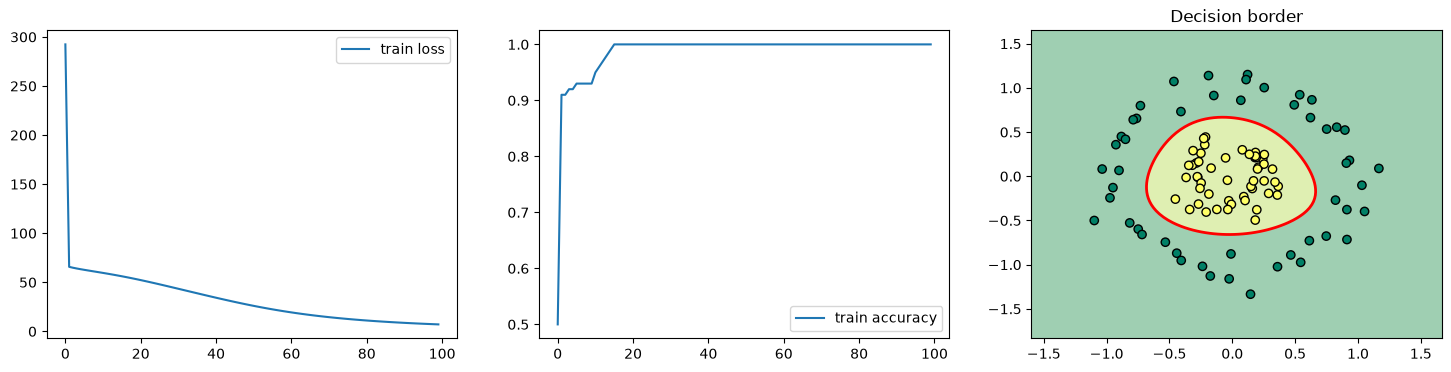

In [26]:
parameters = neural_network(X, y, hidden_layers=(32, 32, 32), lr = 0.1, n_iter = 1000)